# BIL545 · Proje 2 · Vizeden finale kadarki konular (9.–12. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Final notu** · Teslim ve sunum: **14. hafta**

Bu defter projenin şablonudur. Grubunuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje2/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

Proje 2, Proje 1'in çıktılarından başlar.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi
| | Ad Soyad | Öğrenci no |
|---|---|---|
| Üye 1 | [Grup dolduracak] | |
| Üye 2 (varsa) | [Grup dolduracak] | |
| Üye 3 (varsa) | [Grup dolduracak] | |
| Üye 4 (varsa) | [Grup dolduracak] | |
| Üye 5 (varsa) | [Grup dolduracak] | |

**Grup adı:** [Grup dolduracak]  
**GitHub deposu:** https://github.com/sahingngrdu/Sat-n-alma-Niyeti  
**Seçilen konu:** 9.5 — Online alışverişte satın alma niyeti  
**Grup tipi:** Ek Paket 2 ataması nedeniyle 5 kişi varsayılmıştır; grup büyüklüğünü doğrulayın.  
**Veri kümesi ve sorumuz:** Bir e-ticaret oturumundaki gezinme davranışları, oturumun satın almayla bitmesini ne ölçüde öngörür?


## Hazırlık

In [1]:
import sys, random, numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse import hstack
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans, DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, silhouette_score, adjusted_rand_score)
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, ShuffleSplit, cross_validate
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)

Python       3.11.9
numpy        2.4.6
pandas       3.1.1
scikit-learn 1.9.1


## Proje 1'den devralınanlar ve düzeltmeler (%10)

Bu çalışma alanında Proje 1 defteri, seçilen nihai model ve öğretim üyesi geri bildirimi bulunmadığı için bunları varmış gibi göstermiyoruz. Aynı UCI veri kümesiyle bu defterde geçici, tekrarlanabilir bir sınıflandırma hattı yeniden kurulmuştur. Aşağıdaki Proje 2 analizlerinde bu model referans olarak kullanılıyor; gerçek Proje 1'de farklı bir model/ön işleme seçildiyse bu hücre ve ona bağlı sonuçlar Proje 1 çıktılarıyla güncellenmelidir.

**Geri bildirimle yapılan değişiklik:** Proje 1 geri bildirimi paylaşılmadı; bu yüzden değişiklik ve etkisi hakkında doğrulanabilir bir iddia verilemiyor.  
**Geçici referans model:** Sayısal ve kategorik ön işleme Pipeline içinde; sınıf ağırlıklı Random Forest; tabakalı %25 test bölmesi. Sınıf dengesizliği nedeniyle doğruluk yerine Average Precision, ROC-AUC, balanced accuracy ve macro-F1 raporlanıyor. PageValues'ın tahmin anında güvenli biçimde mevcut olup olmadığı net olmadığı ve dönüşüm hedefiyle güçlü ilişkili olabileceği için ana referans hattından çıkarılmış; Ek Paket 2'de duyarlılık olarak ayrıca sınanmıştır.


In [2]:
# Colab'da ucimlrepo kurulur. CSV defter klasöründe/yüklenmişse onu kullan; aksi halde UCI'dan indir.
!pip -q install ucimlrepo

from pathlib import Path
from ucimlrepo import fetch_ucirepo

LOCAL_CSV = Path("online_shoppers_intention.csv")
if LOCAL_CSV.exists():
    raw_df = pd.read_csv(LOCAL_CSV)
    DATA_SOURCE_USED = "Yüklenen online_shoppers_intention.csv"
else:
    uci_dataset = fetch_ucirepo(id=468)
    raw_df = uci_dataset.data.features.copy()
    raw_df["Revenue"] = uci_dataset.data.targets["Revenue"].to_numpy()
    DATA_SOURCE_USED = "UCI Machine Learning Repository, dataset id=468"

NUMERIC_FEATURES = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
CATEGORICAL_FEATURES = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
TARGET = "Revenue"
required = NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET]
missing_columns = sorted(set(required) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Veri setinde eksik sütunlar: {missing_columns}")

def binary_target(series):
    if pd.api.types.is_bool_dtype(series):
        return series.astype(int)
    if pd.api.types.is_numeric_dtype(series):
        values = set(pd.Series(series).dropna().unique())
        if values.issubset({0, 1}):
            return series.astype(int)
    mapped = series.astype(str).str.strip().str.lower().map({
        "true": 1, "false": 0, "yes": 1, "no": 0, "1": 1, "0": 0
    })
    if mapped.isna().any():
        raise ValueError("Revenue ikili hedefe çevrilemedi; değerleri inceleyin.")
    return mapped.astype(int)

df = raw_df[required].copy()
df[TARGET] = binary_target(df[TARGET])
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y = df[TARGET].copy()
REFERENCE_FEATURES = [c for c in X.columns if c != "PageValues"]

def make_preprocessor(feature_cols=None, scale_numeric=True):
    feature_cols = list(feature_cols) if feature_cols is not None else list(REFERENCE_FEATURES)
    numeric_cols = [c for c in NUMERIC_FEATURES if c in feature_cols]
    categorical_cols = [c for c in CATEGORICAL_FEATURES if c in feature_cols]
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    categorical_steps = [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(numeric_steps), numeric_cols),
            ("cat", Pipeline(categorical_steps), categorical_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )

BASE_ESTIMATOR = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
    random_state=SEED, n_jobs=-1,
)

def make_model(feature_cols=None):
    return Pipeline([
        ("preprocess", make_preprocessor(feature_cols=feature_cols)),
        ("classifier", clone(BASE_ESTIMATOR)),
    ])

def binary_metrics(y_true, y_pred, y_prob):
    return {
        "Average Precision": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "Recall (purchase)": recall_score(y_true, y_pred, zero_division=0),
        "Precision (purchase)": precision_score(y_true, y_pred, zero_division=0),
    }

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
model_reference = make_model()
model_reference.fit(X_train, y_train)
test_pred = model_reference.predict(X_test)
test_prob = model_reference.predict_proba(X_test)[:, 1]

print("Veri kaynağı:", DATA_SOURCE_USED)
print(f"Gözlem: {len(df):,} | Öznitelik: {X.shape[1]} | yinelenen satır: {int(df.duplicated().sum()):,}")
print(f"Satın alma oranı: {y.mean():.1%}; satın almama: {(1-y.mean()):.1%}")
print("Eksik hücre sayısı:", int(df.isna().sum().sum()))
display(pd.DataFrame([binary_metrics(y_test, test_pred, test_prob)], index=["Geçici test referansı"]).round(3))



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Veri kaynağı: Yüklenen online_shoppers_intention.csv
Gözlem: 12,330 | Öznitelik: 17 | yinelenen satır: 125
Satın alma oranı: 15.5%; satın almama: 84.5%
Eksik hücre sayısı: 0


,Average Precision,ROC-AUC,Balanced accuracy,Macro-F1,Recall (purchase),Precision (purchase)
Geçici test referansı,0.362,0.763,0.595,0.612,0.245,0.447


# Bölüm 1 · Kümeleme (ağırlık 25)

**Makale:** Ben-Hur, Elisseeff ve Guyon (2002), “A stability based method for discovering structure in clustered data”.

**Okuma notu:** Makale, kümelerin gerçek yapıyı yansıtıp yansıtmadığını veri alt örneklemleri veya gürültü gibi pertürbasyonlar altında çözümlerin kararlılığıyla inceler. Farklı alt örneklemlerde benzer atamalar, yapının daha tekrarlanabilir olduğuna işaret eder; kararlılık, uygun küme sayısını seçmeye ve veri içinde belirgin bir yapı bulunmadığını görmeye de yardım eder. Bu projede ARI, aynı gözlemler için alt örneklem modellerinin atamalarını karşılaştırır; tek başına iş açısından “gerçek segment” kanıtı sayılmaz.


### 1.1 Kümeleme eğilimi ve ölçekleme
Hopkins istatistiğini ve ölçeklenmemiş/ölçeklenmiş uzaklıkların küme ayrımına etkisini inceliyoruz. Kategorik kodlar kategorik kabul edilip one-hot kodlanır; Revenue küme kurulumuna girmez. Hopkins sonucu, one-hot ve sınır kutusundan örnekleme nedeniyle bir tanı göstergesi olarak yorumlanmalıdır.


In [3]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy import sparse

cluster_preprocessor = make_preprocessor()
Z_sparse = clone(cluster_preprocessor).fit_transform(X)
Z = Z_sparse.toarray() if sparse.issparse(Z_sparse) else np.asarray(Z_sparse)

def hopkins_statistic(data, sample_size=300, random_state=SEED):
    rng = np.random.default_rng(random_state)
    n = min(sample_size, max(20, len(data)//10))
    real_idx = rng.choice(len(data), size=n, replace=False)
    synthetic = rng.uniform(data.min(axis=0), data.max(axis=0), size=(n, data.shape[1]))
    nn = NearestNeighbors(n_neighbors=2, n_jobs=-1).fit(data)
    real_dist = nn.kneighbors(data[real_idx], n_neighbors=2)[0][:, 1]
    synthetic_dist = nn.kneighbors(synthetic, n_neighbors=1)[0][:, 0]
    return synthetic_dist.sum() / (synthetic_dist.sum() + real_dist.sum())

hopkins_value = hopkins_statistic(Z)
unscaled_preprocessor = make_preprocessor(scale_numeric=False)
Z_unscaled_raw = clone(unscaled_preprocessor).fit_transform(X)
Z_unscaled = Z_unscaled_raw.toarray() if sparse.issparse(Z_unscaled_raw) else np.asarray(Z_unscaled_raw)

rng = np.random.default_rng(SEED)
scale_sample = rng.choice(len(X), size=min(1800, len(X)), replace=False)
scale_rows = []
for label, matrix in [("Sayısal ölçekleme yok", Z_unscaled), ("Sayısal ölçekleme var", Z)]:
    km = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(matrix)
    sil = silhouette_score(matrix[scale_sample], km.predict(matrix[scale_sample]))
    scale_rows.append({
        "Kurulum": label, "Inertia": km.inertia_,
        "Silhouette (örneklem)": sil,
    })
scale_effect = pd.DataFrame(scale_rows).set_index("Kurulum")
print(f"Hopkins istatistiği (300'e kadar oturum): {hopkins_value:.3f}")
display(scale_effect.round(3))


Hopkins istatistiği (300'e kadar oturum): 0.911


,Inertia,Silhouette (örneklem)
Kurulum,,
Sayısal ölçekleme yok,6.023411e+09,0.626
Sayısal ölçekleme var,1.012584e+05,0.219


**Yorum:** Hopkins istatistiği 0.911 (300 oturumluk örneklem) bu dönüştürülmüş uzayda kümelenme eğilimine işaret ediyor; one-hot sütunlarla sınır kutusundan sentetik örnek üretimi değeri yükseltebileceğinden tek başına kanıt değildir. k=5 karşılaştırmasında silhouette ölçekleme olmadan 0.626, sayısalları ölçekleyince 0.219 oldu. Ölçeklenmemiş uzaklıklarda uzun süre/sayım sütunları diğer özellikleri bastırabildiği için sonraki KMeans analizlerinde ölçeklenmiş kurulum kullanıldı.

### 1.2 k seçimi
Dirsek eğrisi ile 70% alt örneklemlerdeki kümeleme kararlılığını birlikte karşılaştırıyoruz. Kararlılık, farklı alt örneklem modellerinin aynı sabit gözlem kümesindeki etiketleri arasındaki Adjusted Rand Index (ARI) ortalamasıdır.


,Inertia,Silhouette (örneklem),Kararlılık ARI ortalama,Kararlılık ARI std
k,,,,
2,138859.128,0.318,0.945,0.039
3,119201.150,0.307,0.953,0.026
4,108841.901,0.268,0.750,0.259
5,101258.388,0.220,0.918,0.074
6,95355.351,0.221,0.837,0.133
7,91423.718,0.134,0.760,0.159
8,87741.696,0.135,0.624,0.156
9,84283.356,0.137,0.903,0.054


Dirsek adayı k=2; en kararlı k=3; sonraki profilleme için k=3.


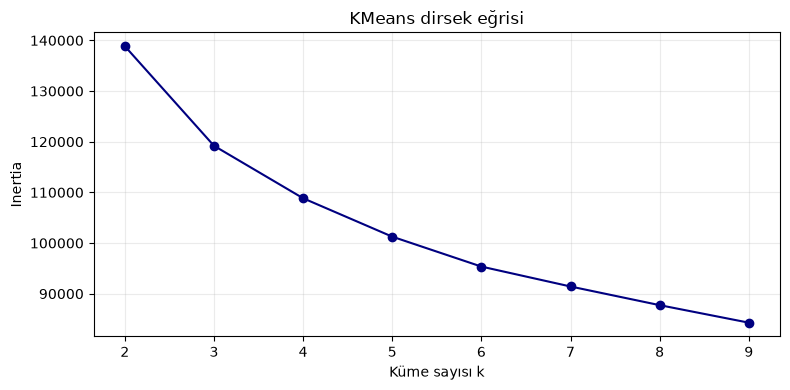

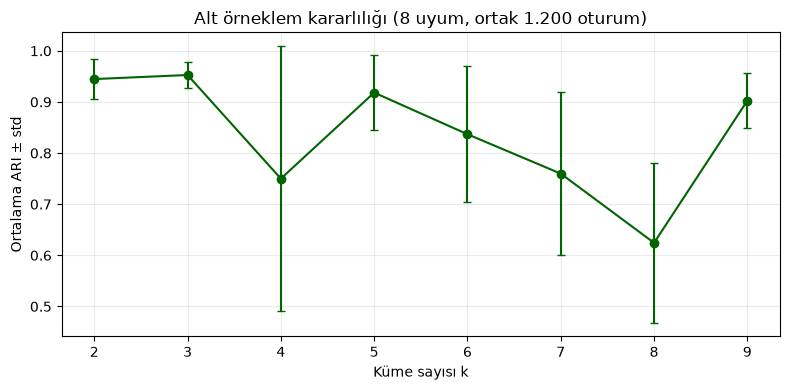

In [4]:
from sklearn.model_selection import ShuffleSplit
from sklearn.metrics import adjusted_rand_score

K_VALUES = list(range(2, 10))
rng = np.random.default_rng(SEED)
sil_idx = rng.choice(len(X), size=min(2200, len(X)), replace=False)
inertia_values, silhouette_values = [], []
for k in K_VALUES:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inertia_values.append(km.inertia_)
    silhouette_values.append(silhouette_score(Z[sil_idx], km.predict(Z[sil_idx])))

common_idx = np.random.default_rng(SEED+1).choice(
    len(X), size=min(1200, len(X)), replace=False
)
pool_idx = np.setdiff1d(np.arange(len(X)), common_idx)
stability_splits = list(ShuffleSplit(
    n_splits=8, train_size=0.70, random_state=SEED
).split(pool_idx))
stability_means, stability_stds = [], []
for k in K_VALUES:
    common_predictions = []
    for local_train_idx, _ in stability_splits:
        train_idx = pool_idx[local_train_idx]
        km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(Z[train_idx])
        common_predictions.append(km.predict(Z[common_idx]))
    pairwise_ari = [
        adjusted_rand_score(common_predictions[i], common_predictions[j])
        for i in range(len(common_predictions))
        for j in range(i+1, len(common_predictions))
    ]
    stability_means.append(np.mean(pairwise_ari))
    stability_stds.append(np.std(pairwise_ari, ddof=1))

k_results = pd.DataFrame({
    "Inertia": inertia_values,
    "Silhouette (örneklem)": silhouette_values,
    "Kararlılık ARI ortalama": stability_means,
    "Kararlılık ARI std": stability_stds,
}, index=K_VALUES)
k_results.index.name = "k"
display(k_results.round(3))

# Dirsek: ölçeklenmiş eğrinin uç noktalarını birleştiren doğrudan en büyük uzaklık.
x_norm = (np.array(K_VALUES)-K_VALUES[0])/(K_VALUES[-1]-K_VALUES[0])
y_norm = (np.array(inertia_values)-inertia_values[-1])/(inertia_values[0]-inertia_values[-1])
elbow_distance = y_norm - (1-x_norm)
K_ELBOW = int(K_VALUES[int(np.argmax(elbow_distance))])
K_STABILITY = int(k_results["Kararlılık ARI ortalama"].idxmax())
K_FINAL = K_STABILITY
print(f"Dirsek adayı k={K_ELBOW}; en kararlı k={K_STABILITY}; sonraki profilleme için k={K_FINAL}.")
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(K_VALUES, inertia_values, marker="o", color="navy")
ax1.set_xlabel("Küme sayısı k"); ax1.set_ylabel("Inertia"); ax1.set_title("KMeans dirsek eğrisi")
ax1.grid(alpha=.25); plt.tight_layout(); plt.show()
fig, ax2 = plt.subplots(figsize=(8,4))
ax2.errorbar(K_VALUES, stability_means, yerr=stability_stds, marker="o", capsize=3, color="darkgreen")
ax2.set_xlabel("Küme sayısı k"); ax2.set_ylabel("Ortalama ARI ± std")
ax2.set_title("Alt örneklem kararlılığı (8 uyum, ortak 1.200 oturum)")
ax2.grid(alpha=.25); plt.tight_layout(); plt.show()


**Yorum:** Dirsek k=2'yi önerirken en yüksek alt örneklem kararlılığı k=3'te görüldü (ARI 0.953 ± 0.026; k=2 için 0.945 ± 0.039). k=3, küçük kararlılık farkı ve daha ayrıntılı profiller sunması nedeniyle seçildi; tek doğru küme sayısı olarak yorumlanmamalıdır. Sekiz alt örneklem ve sabit tohum kullanıldı.

### 1.3 Yöntemler
KMeans ile tüm oturumları kümeleyip, yoğunluk temelli DBSCAN'i karşılaştırıyoruz. DBSCAN yüksek boyutlu uzayda maliyetli olabileceğinden 3.000 oturumluk sabit örneklemde uygulanır; epsilon, 10'uncu komşu uzaklığının 90. yüzdeliğiyle seçilir ve bu seçim bir duyarlılık sınırlamasıdır.


In [5]:
kmeans_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(Z)
kmeans_labels = kmeans_final.labels_

db_sample_idx = np.random.default_rng(SEED+2).choice(
    len(X), size=min(3000, len(X)), replace=False
)
Z_db = Z[db_sample_idx]
neighbor_distances = NearestNeighbors(n_neighbors=11, n_jobs=-1).fit(Z_db).kneighbors(Z_db)[0]
eps_value = float(np.quantile(neighbor_distances[:, -1], 0.90))
dbscan = DBSCAN(eps=eps_value, min_samples=10, n_jobs=-1)
db_labels = dbscan.fit_predict(Z_db)
db_clusters = sorted(set(db_labels) - {-1})
db_noise_share = float(np.mean(db_labels == -1))
db_silhouette = np.nan
non_noise = db_labels != -1
if len(db_clusters) >= 2 and non_noise.sum() > 50:
    db_silhouette = silhouette_score(
        Z_db[non_noise], db_labels[non_noise],
        sample_size=min(1200, int(non_noise.sum())), random_state=SEED
    )
km_silhouette = silhouette_score(
    Z[sil_idx], kmeans_final.predict(Z[sil_idx])
)
method_summary = pd.DataFrame([
    {"Yöntem": f"KMeans (k={K_FINAL})", "Küme sayısı": K_FINAL,
     "Gürültü oranı": 0.0, "Silhouette": km_silhouette, "Örneklem": len(X)},
    {"Yöntem": "DBSCAN", "Küme sayısı": len(db_clusters),
     "Gürültü oranı": db_noise_share, "Silhouette": db_silhouette, "Örneklem": len(db_labels)},
])
display(method_summary.round(3))
print(f"DBSCAN epsilon={eps_value:.3f}, min_samples=10")


,Yöntem,Küme sayısı,Gürültü oranı,Silhouette,Örneklem
0,KMeans (k=3),3,0.00,0.307,12330
1,DBSCAN,1,0.05,NaN,3000


DBSCAN epsilon=2.959, min_samples=10


**Yorum:** Ölçeklenmiş uzayda KMeans k=3 için örneklem silhouette 0.307 verdi. DBSCAN, 3.000 oturumda epsilon=2.959 ile tek yoğun küme buldu; oturumların %5.1'ini gürültü saydı. Yalnız bir küme çıktığı için DBSCAN silhouette tanımsızdır. Bu parametrelerle DBSCAN çoklu segment üretmedi; yüksek boyut ve epsilon seçimi sonucu etkileyebilir.

### 1.4 Profiller ve savunma
KMeans profillerinde oturum davranış özetleri ve satın alma oranı gösterilir. Revenue yalnızca profilleme/savunmada kullanılır; küme kurulumuna girmemiştir.


In [6]:
profile_df = df.copy()
profile_df["cluster"] = kmeans_labels
profile_summary = profile_df.groupby("cluster").agg(
    oturum=("Revenue", "size"),
    satın_alma_oranı=("Revenue", "mean"),
    **{c:(c,"mean") for c in NUMERIC_FEATURES if c != "PageValues"}
).round(3)
display(profile_summary)

category_modes = profile_df.groupby("cluster")[CATEGORICAL_FEATURES].agg(
    lambda s: s.mode(dropna=True).iloc[0] if not s.mode(dropna=True).empty else np.nan
)
print("Her kümenin kategorik sütun modları:")
display(category_modes)


,oturum,satın_alma_oranı,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay
cluster,,,,,,,,,,,
0,9675,0.151,1.720,51.821,0.219,8.206,23.964,877.956,0.009,0.032,0.062
1,1602,0.278,7.403,308.153,2.541,215.708,97.495,3855.475,0.006,0.020,0.029
2,1053,0.006,0.047,1.393,0.015,0.087,3.053,57.475,0.166,0.180,0.108


Her kümenin kategorik sütun modları:


,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
cluster,,,,,,,
0,May,2,2,1,2,Returning_Visitor,False
1,Nov,2,2,1,2,Returning_Visitor,False
2,May,2,2,1,1,Returning_Visitor,False


**Yorum — “Bu kümeler gerçek mi?”** KMeans profillerinde 9.675 oturumluk kümenin satın alma oranı %15.1; 1.602 oturumluk daha yoğun gezinme kümesinin oranı %27.8; 1.053 oturumluk kısa gezinme/yüksek bounce-exit kümesinin oranı %0.6'dır. Son kümede ortalama 3 ürün sayfası ve 57 saniye ürün sayfası süresi varken ikinci kümede bunlar yaklaşık 97 sayfa ve 3.855 saniyedir. Bu farklar oturum profillerini betimler; gerçek ve kalıcı kullanıcı tipleri ya da nedensel satın alma etkisi olduklarını göstermez. Kümeler ölçekleme, örneklem ve algoritma seçimine bağlıdır.

# Bölüm 2 · Aykırı gözlem (ağırlık 20)

**Makale:** Liu, Ting ve Zhou (2008), “Isolation Forest”.

**Okuma notu:** Isolation Forest, normal örnekleri modelleyip sapmaları dolaylı ölçmek yerine gözlemleri rastgele bölmelerle izole eder. Az ve farklı gözlemler ortalama olarak daha kısa ağaç yollarıyla izole edilir; yöntem alt örnekleme sayesinde büyük veri kümelerinde verimli olacak biçimde tasarlanmıştır. Bu projede skorlar olağandışılık sıralamasıdır, “hata” etiketi değildir; LOF ile farklı anormallik bakış açılarını karşılaştırıyoruz.


### 2.1 İki yöntem
Isolation Forest küresel izolasyon, LOF yerel komşuluk yoğunluğu kullanır. Sıralama uyumunu Spearman korelasyonuyla ölçüyoruz.


In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from scipy.stats import spearmanr


**Yorum:** IF ve LOF sıra korelasyonu Spearman ρ=0.345'tir (p<0.001); pozitif ama sınırlı uyum, küresel izolasyon ve yerel yoğunluk yöntemlerinin farklı oturumları öne çıkardığını gösterir. Bu nedenle tek bir “doğru aykırı sırası” yoktur; iki skor ayrı tanı sinyalleri olarak incelenmiştir.

### 2.2 En aykırı 20 kayıt
Veri hata kontrolleri aralık kurallarına dayanır; otomatik aralık ihlali bulunmaması, davranışın olağan olduğu anlamına gelmez. Kayıtlar kimlik taşımadığından örnekler oturum özellikleriyle gösterilir.


In [8]:
pca_out = PCA(n_components=min(15, Z.shape[1]), random_state=SEED)
Z_out = pca_out.fit_transform(Z)
iso = IsolationForest(
    n_estimators=300, contamination=0.02, random_state=SEED, n_jobs=-1
).fit(Z_out)
iso_score = -iso.decision_function(Z_out)

lof = LocalOutlierFactor(n_neighbors=35, contamination=0.02, n_jobs=-1)
lof_labels = lof.fit_predict(Z_out)
lof_score = -lof.negative_outlier_factor_

score_table = pd.DataFrame({
    "IF score": iso_score,
    "IF rank": pd.Series(iso_score).rank(ascending=False).to_numpy(),
    "LOF score": lof_score,
    "LOF rank": pd.Series(lof_score).rank(ascending=False).to_numpy(),
}, index=X.index)
rho, p_value = spearmanr(score_table["IF rank"], score_table["LOF rank"])
print(f"IF–LOF sıra uyumu: Spearman rho={rho:.3f}, p={p_value:.3g}")

top20 = score_table.nlargest(20, "IF score").join(df)
def quality_flags(row):
    flags = []
    for c in ["Administrative","Informational","ProductRelated",
              "Administrative_Duration","Informational_Duration","ProductRelated_Duration","PageValues"]:
        if pd.notna(row[c]) and row[c] < 0:
            flags.append(f"{c}<0")
    for c in ["BounceRates","ExitRates","SpecialDay"]:
        if pd.notna(row[c]) and not (0 <= row[c] <= 1):
            flags.append(f"{c} [0,1] dışında")
    return "; ".join(flags) if flags else "Otomatik aralık ihlali yok; olağandışı ama geçerli olabilir"

top20["Veri kontrolü"] = top20.apply(quality_flags, axis=1)
display(top20[[
    "IF score","LOF score","Administrative","Informational","ProductRelated",
    "ProductRelated_Duration","BounceRates","ExitRates","PageValues",
    "Month","VisitorType","Weekend","Revenue","Veri kontrolü"
]].round(3))


IF–LOF sıra uyumu: Spearman rho=0.345, p=0


,IF score,LOF score,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Month,VisitorType,Weekend,Revenue,Veri kontrolü
5152,0.176,4.104,17,24,705,43171.233,0.005,0.015,0.764,May,Returning_Visitor,True,0,Otomatik aralık ihlali yok; olağandışı ama geç...
8071,0.138,4.556,5,6,449,63973.522,0.001,0.028,0.000,Dec,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...
10302,0.136,1.483,4,5,74,8981.580,0.003,0.043,0.000,Dec,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...
11470,0.131,1.465,8,6,14,1805.425,0.000,0.031,10.900,Dec,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...
5916,0.125,1.887,12,4,439,21857.046,0.004,0.012,11.439,Sep,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...
7662,0.124,1.823,10,7,414,23888.810,0.010,0.027,1.034,Sep,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...
5512,0.122,1.525,3,5,21,378.400,0.030,0.031,0.000,Jul,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...
4253,0.120,1.681,3,1,362,13259.294,0.003,0.009,0.000,May,Returning_Visitor,True,0,Otomatik aralık ihlali yok; olağandışı ama geç...
9901,0.116,1.452,0,6,423,17086.234,0.006,0.022,0.253,Nov,Returning_Visitor,True,0,Otomatik aralık ihlali yok; olağandışı ama geç...
9514,0.115,1.264,0,1,19,1401.083,0.020,0.050,0.000,Dec,Returning_Visitor,False,0,Otomatik aralık ihlali yok; olağandışı ama geç...


**Yorum:** Isolation Forest'ın en yüksek skorlu 20 oturumunda tanımladığımız negatif sayım/süre/PageValues ve [0,1] dışı oran kurallarına göre otomatik aralık ihlali çıkmadı. Buna rağmen bazı kayıtlar yüzlerce ürün sayfası ve on binlerce saniye ürün sayfası süresi içeriyor; bunlar hata oldukları kanıtlanmış kayıtlar değil, kaynak/veri toplama bilgisiyle ayrıca incelenmesi gereken uç profillerdir. İlk 20'de hem Revenue=0 hem Revenue=1 örnekleri bulunması, aykırılık skorunun yanlış etiket anlamına gelmediğini de gösteriyor.

### 2.3 Modele etkisi
Eğitim bölümünde Isolation Forest ile en yüksek %2 anomali skorlu örnekleri çıkarıp aynı dokunulmamış test setinde geçici referans modelin sonuçlarıyla karşılaştırıyoruz. P1 modeli sağlanmadığı için test edilen model geçici yeniden kurulumdur.


In [9]:
train_pre = clone(make_preprocessor()).fit(X_train)
Z_train = train_pre.transform(X_train)
Z_train = Z_train.toarray() if sparse.issparse(Z_train) else np.asarray(Z_train)
pca_train = PCA(n_components=min(15, Z_train.shape[1]), random_state=SEED).fit_transform(Z_train)
iso_train = IsolationForest(
    n_estimators=300, contamination=0.02, random_state=SEED, n_jobs=-1
).fit(pca_train)
train_scores = -iso_train.decision_function(pca_train)
cutoff = np.quantile(train_scores, 0.98)
keep_train = train_scores < cutoff

model_filtered = make_model()
model_filtered.fit(X_train.loc[keep_train], y_train.loc[keep_train])
filtered_pred = model_filtered.predict(X_test)
filtered_prob = model_filtered.predict_proba(X_test)[:,1]

outlier_effect = pd.DataFrame([
    binary_metrics(y_test, test_pred, test_prob),
    binary_metrics(y_test, filtered_pred, filtered_prob),
], index=["Tüm eğitim oturumları", "En aykırı %2 eğitim oturumları çıkarıldı"])
print(f"Eğitimde çıkarılan oran: {(~keep_train).mean():.1%}; test seti aynı bırakıldı.")
display(outlier_effect.round(3))


Eğitimde çıkarılan oran: 2.0%; test seti aynı bırakıldı.


,Average Precision,ROC-AUC,Balanced accuracy,Macro-F1,Recall (purchase),Precision (purchase)
Tüm eğitim oturumları,0.362,0.763,0.595,0.612,0.245,0.447
En aykırı %2 eğitim oturumları çıkarıldı,0.371,0.767,0.601,0.618,0.260,0.448


**Yorum:** Eğitimdeki en yüksek skorlu %2 çıkarıldığında aynı test setinde Average Precision 0.362'den 0.371'e, balanced accuracy 0.595'ten 0.601'e ve satın alma recall'ı 0.245'ten 0.260'a çıktı; precision 0.447'den 0.448'e değişti. Bu küçük artış, bu geçici model ve eşik altında aykırı oturumları topluca silmenin zorunlu olmadığını düşündürür; “anomali” etiketi veri hatası veya temizlenmesi gereken oturum kanıtı değildir.

# Bölüm 3 · Alt grup analizi ve adillik (ağırlık 15)

**Makale:** Mehrabi, Morstatter, Saxena, Lerman ve Galstyan (2021), “A Survey on Bias and Fairness in Machine Learning”.

**Okuma notu:** Derleme, makine öğrenmesinde yanlılığın veri toplama/temsil, etiket/ölçüm, modelleme ve kullanım aşamalarında ortaya çıkabileceğini ve “adillik” için tek bir evrensel ölçüt bulunmadığını tartışır. Adillik ölçütleri hedef, bağlam ve etkilenen gruplara göre anlam kazanır. Bu veri yaş/cinsiyet gibi hassas kişisel özellikler içermiyor; bu nedenle cinsiyet veya demografik adillik iddiası yerine Month, VisitorType ve Weekend gruplarında performans farklarını alt grup analizi olarak raporluyoruz.


### 3.0 Alt gruplar
**Seçim:** Alt grup analizi. Veride hassas demografik kişi bilgisi yok. Month, VisitorType ve Weekend, oturumun zaman/ziyaretçi bağlamını temsil ediyor. Bunlar hassas grup yerine iş davranışı alt gruplarıdır; sonuçlar “model adildir” biçiminde genellenmeyecektir.


In [10]:
subgroup_fields = ["Month", "VisitorType", "Weekend"]
test_results = pd.DataFrame({
    "truth": y_test.to_numpy(),
    "prediction": test_pred,
    "probability": test_prob,
}, index=X_test.index)

def subgroup_metrics(frame, group_col, min_n=30):
    rows = []
    joined = frame.join(X_test[[group_col]])
    for group_value, part in joined.groupby(group_col, dropna=False):
        if len(part) < min_n:
            continue
        yt = part["truth"].to_numpy()
        yp = part["prediction"].to_numpy()
        pp = part["probability"].to_numpy()
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0,1]).ravel()
        rows.append({
            "Alt grup": str(group_value),
            "N": len(part),
            "Satın alma oranı": yt.mean(),
            "Average Precision": average_precision_score(yt, pp) if len(np.unique(yt)) > 1 else np.nan,
            "Recall": tp/(tp+fn) if tp+fn else np.nan,
            "False-negative rate": fn/(tp+fn) if tp+fn else np.nan,
            "False-positive rate": fp/(fp+tn) if fp+tn else np.nan,
            "Balanced accuracy": balanced_accuracy_score(yt, yp) if len(np.unique(yt)) > 1 else np.nan,
        })
    return pd.DataFrame(rows).sort_values("Alt grup")



**Yorum:** Test bölümünde ziyaretçi türü alt grupları 429 yeni ve 2.641 geri dönen oturumdan; hafta içi/sonu grupları 2.346 ve 737 oturumdan oluşuyor. Ay gruplarının büyüklüğü 43–814 arasında değişiyor. Bu yüzden özellikle küçük aylardaki metrikleri satın alma oranı ve n ile birlikte okumak gerekir. Gruplar davranış/zaman bağlamıdır; hassas demografik grupları temsil etmez.

### 3.1 Alt gruplarda hata
Aşağıdaki tablolar geçici referans modelin aynı test bölmesindeki hata oranlarını gösterir. Birincil karşılaştırma satın alma sınıfını kaçıran false-negative rate'tir.


In [11]:
subgroup_tables = {}
for field in subgroup_fields:
    subgroup_tables[field] = subgroup_metrics(test_results, field, min_n=30)
    print(f"Alt grup: {field}")
    display(subgroup_tables[field].round(3))


Alt grup: Month


,Alt grup,N,Satın alma oranı,Average Precision,Recall,False-negative rate,False-positive rate,Balanced accuracy
0,Aug,114,0.149,0.277,0.059,0.941,0.031,0.514
1,Dec,431,0.104,0.263,0.222,0.778,0.039,0.592
2,Feb,43,0.023,0.167,0.000,1.000,0.000,0.500
3,Jul,113,0.204,0.391,0.000,1.000,0.000,0.500
4,June,84,0.095,0.308,0.125,0.875,0.000,0.562
5,Mar,462,0.089,0.284,0.073,0.927,0.012,0.531
6,May,814,0.111,0.383,0.200,0.800,0.025,0.588
7,Nov,785,0.270,0.434,0.382,0.618,0.176,0.603
8,Oct,134,0.164,0.289,0.091,0.909,0.009,0.541
9,Sep,103,0.175,0.435,0.056,0.944,0.024,0.516


Alt grup: VisitorType


,Alt grup,N,Satın alma oranı,Average Precision,Recall,False-negative rate,False-positive rate,Balanced accuracy
0,New_Visitor,429,0.256,0.461,0.382,0.618,0.147,0.617
1,Returning_Visitor,2641,0.138,0.328,0.198,0.802,0.042,0.578


Alt grup: Weekend


,Alt grup,N,Satın alma oranı,Average Precision,Recall,False-negative rate,False-positive rate,Balanced accuracy
0,False,2346,0.150,0.368,0.252,0.748,0.049,0.601
1,True,737,0.168,0.352,0.226,0.774,0.077,0.575


**Yorum:** Sabit 0.5 eşiğinde false-negative rate aylar arasında 0.618–1.000, ziyaretçi türünde 0.618 (yeni)–0.802 (geri dönen), hafta sonu durumunda 0.748–0.774 aralığındadır. Şubat grubunda n=43 ve yalnızca bir satın alma vardır; Temmuz'da da satın almaların hiçbiri bu eşikte yakalanmamıştır. Geri dönen ziyaretçilerde recall 0.198, yenilerde 0.382'dir. Bu tek test bölmesindeki betimsel farklar kesin veya istatistiksel olarak doğrulanmış adillik sonuçları değildir.

### 3.2 Nedenler
Farklar temsil (grupların büyüklüğü), ölçüm (oturum davranışlarından türetilmiş metrikler), hedefin kapsamı (oturum satın almayla bitti mi?) ve mevsimsel/ziyaretçi bağlamıyla ilişkili olabilir. Bu CSV'den bu nedenlerin hangisinin nedensel olduğunu belirleyemeyiz.


In [12]:
gap_rows = []
for field, table in subgroup_tables.items():
    for metric in ["False-negative rate","False-positive rate","Average Precision"]:
        vals = table[metric].dropna()
        gap_rows.append({
            "Gruplama": field, "Ölçüt": metric,
            "En düşük": vals.min() if len(vals) else np.nan,
            "En yüksek": vals.max() if len(vals) else np.nan,
            "Aralık": vals.max()-vals.min() if len(vals) else np.nan,
            "En küçük grup n": int(table["N"].min()) if len(table) else 0,
        })
gap_summary = pd.DataFrame(gap_rows)
display(gap_summary.round(3))


,Gruplama,Ölçüt,En düşük,En yüksek,Aralık,En küçük grup n
0,Month,False-negative rate,0.618,1.000,0.382,43
1,Month,False-positive rate,0.000,0.176,0.176,43
2,Month,Average Precision,0.167,0.435,0.268,43
3,VisitorType,False-negative rate,0.618,0.802,0.184,429
4,VisitorType,False-positive rate,0.042,0.147,0.106,429
5,VisitorType,Average Precision,0.328,0.461,0.133,429
6,Weekend,False-negative rate,0.748,0.774,0.026,737
7,Weekend,False-positive rate,0.049,0.077,0.028,737
8,Weekend,Average Precision,0.352,0.368,0.016,737


**Yorum:** Gözlenen false-negative aralığı hafta sonu gruplarında 0.026, ziyaretçi türünde 0.184, aylarda 0.382'dir; en yüksek değerler küçük veya düşük satın alma oranlı aylarda görülüyor. Temsil, pozitif oranı ve oturum bağlamı bu tabloyu etkileyebilir; mevcut veriden nedenleri ayıramıyoruz. Hassas demografik alanlar olmadığı ve belirsizlik aralıkları hesaplanmadığı için bu analiz adillik sertifikası sunmaz.

# Ek paket 1 · Kümeler ve sınıflandırma (4 ve 5 kişilik gruplar)

Ek Paket 2 görevi verildiği için grup tipi 5 kişi varsayılmıştır; bu varsayım doğruysa Ek Paket 1 de kapsamın parçasıdır. Proje 1 sınıflandırıcısı sağlanmadığından aşağıdaki karşılaştırmalar geçici referans modelle yapılır.


### E1.1 Kümelere göre hata
Kümeleme ve sınıflandırma adımlarını test değerlendirmesine sızıntı yaratmayacak biçimde ayırıyoruz: kümeleyici yalnızca eğitim oturumlarında öğrenilir, test kümeleri eğitim küme merkezlerine atanır.


In [13]:
cluster_pre_train = clone(make_preprocessor()).fit(X_train)
Ztr = cluster_pre_train.transform(X_train)
Zte = cluster_pre_train.transform(X_test)
Ztr = Ztr.toarray() if sparse.issparse(Ztr) else np.asarray(Ztr)
Zte = Zte.toarray() if sparse.issparse(Zte) else np.asarray(Zte)
kmeans_train = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(Ztr)
train_cluster = kmeans_train.labels_
test_cluster = kmeans_train.predict(Zte)

cluster_error_rows = []
for c in sorted(np.unique(test_cluster)):
    mask = test_cluster == c
    yt = y_test.to_numpy()[mask]
    yp = test_pred[mask]
    cluster_error_rows.append({
        "Küme": int(c), "N test": int(mask.sum()),
        "Satın alma oranı": yt.mean(),
        "Hata oranı": np.mean(yp != yt),
        "Recall": recall_score(yt, yp, zero_division=0),
        "False-negative rate": (np.sum((yt==1)&(yp==0))/np.sum(yt==1)) if np.sum(yt==1) else np.nan,
    })
cluster_errors = pd.DataFrame(cluster_error_rows)
display(cluster_errors.round(3))


,Küme,N test,Satın alma oranı,Hata oranı,Recall,False-negative rate
0,0,2400,0.150,0.158,0.199,0.801
1,1,255,0.008,0.008,0.000,1.000
2,2,428,0.266,0.287,0.395,0.605


**Yorum:** Eğitimde öğrenilip testte merkezlere atanan k=3 kümelerde satın alma oranları sırasıyla %15.0, %0.8 ve %26.6'dır. Aynı test bölümündeki false-negative oranları %80.1, %100 ve %60.5'tir; satın alma recall'ı en yüksek kümede bile 0.395'tir. Özellikle ikinci kümenin pozitif örnek sayısı düşüktür; bu nedenle değerleri kesin segment başarımı gibi değil, geçici referans modelin hata örüntüsü olarak okuyun.

### E1.2 Küme bilgisi öznitelik olarak
Küme etiketi sınıflandırma hattının içinde üretilir. Her CV katında ön işleme ve KMeans yalnızca o katın eğitim verisine fit edilir; doğrulama oturumları eğitimde öğrenilmiş merkezlere atanır.


In [14]:
class ClusterFeatureAugmenter(BaseEstimator, TransformerMixin):
    def __init__(self, preprocessor, n_clusters=4, random_state=42):
        self.preprocessor = preprocessor
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y=None):
        self.preprocessor_ = clone(self.preprocessor)
        Zfit = self.preprocessor_.fit_transform(X)
        self.kmeans_ = KMeans(
            n_clusters=self.n_clusters, n_init=10, random_state=self.random_state
        ).fit(Zfit)
        self.encoder_ = OneHotEncoder(
            categories=[np.arange(self.n_clusters)], handle_unknown="ignore"
        )
        self.encoder_.fit(np.arange(self.n_clusters).reshape(-1,1))
        return self

    def transform(self, X):
        Znew = self.preprocessor_.transform(X)
        labels = self.kmeans_.predict(Znew).reshape(-1,1)
        cluster_ohe = self.encoder_.transform(labels)
        return sparse.hstack([Znew, cluster_ohe], format="csr")

cluster_augmented_model = Pipeline([
    ("cluster_features", ClusterFeatureAugmenter(
        preprocessor=make_preprocessor(), n_clusters=K_FINAL, random_state=SEED
    )),
    ("classifier", clone(BASE_ESTIMATOR)),
])
cv_small = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
cluster_cv_rows = []
for name, estimator in [
    ("Tek model, küme özelliği yok", make_model()),
    ("Küme özelliği CV hattında", cluster_augmented_model),
]:
    scores = cross_validate(
        estimator, X, y, cv=cv_small,
        scoring={"AveragePrecision":"average_precision","BalancedAccuracy":"balanced_accuracy"},
        n_jobs=1, error_score="raise"
    )
    cluster_cv_rows.append({
        "Hat": name,
        "Average Precision ort ± std": f"{scores['test_AveragePrecision'].mean():.3f} ± {scores['test_AveragePrecision'].std(ddof=1):.3f}",
        "Balanced accuracy ort ± std": f"{scores['test_BalancedAccuracy'].mean():.3f} ± {scores['test_BalancedAccuracy'].std(ddof=1):.3f}",
    })
display(pd.DataFrame(cluster_cv_rows).set_index("Hat"))


,Average Precision ort ± std,Balanced accuracy ort ± std
Hat,,
"Tek model, küme özelliği yok",0.378 ± 0.026,0.599 ± 0.017
Küme özelliği CV hattında,0.378 ± 0.030,0.598 ± 0.013


**Yorum:** Kat içi küme özelliği, tek modele kıyasla Average Precision ortalamasını 0.378'de değiştirmedi (±std 0.026 ve 0.030); balanced accuracy 0.599'dan 0.598'e geldi (±std 0.017 ve 0.013). Bu CV karşılaştırmasında küme etiketi ölçülebilir katkı sağlamadı. Küme merkezleri ve ön işleme her katta yalnızca eğitim verisinde öğrenildi.

### E1.3 Küme başına model
Aynı eğitim kümesi atamalarına göre ayrı sınıflandırıcılar eğitip, aynı test oturumlarında tek modelle karşılaştırıyoruz. Kümede iki sınıf yoksa/global modelden küçük örnekli kümelerde yedek olarak yararlanılır.


In [15]:
per_cluster_predictions = np.zeros(len(X_test), dtype=int)
per_cluster_probabilities = np.zeros(len(X_test), dtype=float)
cluster_fallbacks = []
for c in sorted(np.unique(train_cluster)):
    train_mask = train_cluster == c
    test_mask = test_cluster == c
    if test_mask.sum() == 0:
        continue
    if train_mask.sum() < 100 or y_train.iloc[np.flatnonzero(train_mask)].nunique() < 2:
        per_cluster_predictions[test_mask] = test_pred[test_mask]
        per_cluster_probabilities[test_mask] = test_prob[test_mask]
        cluster_fallbacks.append(int(c))
        continue
    local_model = make_model().fit(X_train.iloc[np.flatnonzero(train_mask)], y_train.iloc[np.flatnonzero(train_mask)])
    per_cluster_predictions[test_mask] = local_model.predict(X_test.iloc[np.flatnonzero(test_mask)])
    per_cluster_probabilities[test_mask] = local_model.predict_proba(X_test.iloc[np.flatnonzero(test_mask)])[:,1]

separate_model_comparison = pd.DataFrame([
    binary_metrics(y_test, test_pred, test_prob),
    binary_metrics(y_test, per_cluster_predictions, per_cluster_probabilities),
], index=["Tek global model","Kümeye göre ayrı modeller"])
display(separate_model_comparison.round(3))
print("Global model yedeğine düşülen kümeler:", cluster_fallbacks)


,Average Precision,ROC-AUC,Balanced accuracy,Macro-F1,Recall (purchase),Precision (purchase)
Tek global model,0.362,0.763,0.595,0.612,0.245,0.447
Kümeye göre ayrı modeller,0.350,0.759,0.583,0.599,0.220,0.430


Global model yedeğine düşülen kümeler: []


**Yorum:** Aynı test oturumlarında kümeye özel modeller global modelden düşük sonuç verdi: Average Precision 0.350'e karşı 0.362, balanced accuracy 0.583'e karşı 0.595, satın alma recall'ı 0.220'ye karşı 0.245. Bu bölme ve model ayarlarında veriyi kümelere ayırıp daha fazla sınıflandırıcı eğitmek yarar sağlamadı; global model tercih edilir.

# Ek paket 2 · Popüler konular (5 kişilik gruplar)

**Seçim:** Seçenek A — web/oturum davranış analizi. Veri seti sayfa sayısı/süresi, bounce/exit oranları ve oturum bağlamı içerir; ham tıklama dizisi veya kesin zaman damgası içermez. Bu nedenle zaman kayması iddiası kurmak yerine oturum davranışı özelliklerinin modele katkısını ölçüyoruz.


### E2.0 Seçenek
**Seçenek A — web/oturum bilgisi.** UCI veri kümesindeki Administrative, Informational ve ProductRelated sayfa sayıları/süreleri ile BounceRates/ExitRates gibi değişkenler oturum davranışını özetler. Seçim gerekçesi budur. Bu çalışma raw clickstream sırasını veya kesin tarih/saat bilgisini incelemez; ay bilgisi tek başına zamansal dış örneklem testi için yeterli değildir.


In [16]:
WEB_FEATURES = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
]
CONTEXT_FEATURES = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
ALL_FEATURES = WEB_FEATURES + CONTEXT_FEATURES + ["PageValues"]
feature_sets = {
    "Bağlam özellikleri": CONTEXT_FEATURES,
    "Web/oturum davranışı (PageValues hariç)": WEB_FEATURES,
    "Bağlam + web davranışı (PageValues hariç)": WEB_FEATURES + CONTEXT_FEATURES,
    "PageValues tek başına (duyarlılık)": ["PageValues"],
    "Tümü (PageValues dahil, duyarlılık)": ALL_FEATURES,
}
e2_rows = []
for name, cols in feature_sets.items():
    scores = cross_validate(
        make_model(cols), X, y, cv=cv_small,
        scoring={
            "AveragePrecision":"average_precision",
            "BalancedAccuracy":"balanced_accuracy",
            "MacroF1":"f1_macro",
            "ROCAUC":"roc_auc",
        },
        n_jobs=1, error_score="raise"
    )
    row = {"Özellik grubu":name}
    for metric,label in [
        ("AveragePrecision","Average Precision"),
        ("BalancedAccuracy","Balanced accuracy"),
        ("MacroF1","Macro-F1"),
        ("ROCAUC","ROC-AUC"),
    ]:
        vals = scores[f"test_{metric}"]
        row[label+" ort ± std"] = f"{vals.mean():.3f} ± {vals.std(ddof=1):.3f}"
        row[label+" mean"] = vals.mean()
    e2_rows.append(row)
e2_results = pd.DataFrame(e2_rows).set_index("Özellik grubu")
display(e2_results[[c for c in e2_results.columns if "ort ± std" in c]])
context_ap = e2_results.loc["Bağlam özellikleri","Average Precision mean"]
for comparison in [
    "Web/oturum davranışı (PageValues hariç)",
    "Bağlam + web davranışı (PageValues hariç)",
    "PageValues tek başına (duyarlılık)",
    "Tümü (PageValues dahil, duyarlılık)",
]:
    print(f"{comparison} — bağlam hattına göre Average Precision farkı: "
          f"{e2_results.loc[comparison,'Average Precision mean']-context_ap:+.3f}")


,Average Precision ort ± std,Balanced accuracy ort ± std,Macro-F1 ort ± std,ROC-AUC ort ± std
Özellik grubu,,,,
Bağlam özellikleri,0.256 ± 0.017,0.601 ± 0.015,0.568 ± 0.013,0.654 ± 0.012
Web/oturum davranışı (PageValues hariç),0.305 ± 0.011,0.549 ± 0.009,0.555 ± 0.013,0.735 ± 0.008
Bağlam + web davranışı (PageValues hariç),0.378 ± 0.026,0.599 ± 0.017,0.615 ± 0.020,0.782 ± 0.012
PageValues tek başına (duyarlılık),0.538 ± 0.023,0.769 ± 0.013,0.766 ± 0.008,0.798 ± 0.019
"Tümü (PageValues dahil, duyarlılık)",0.740 ± 0.017,0.808 ± 0.016,0.808 ± 0.012,0.929 ± 0.008


Web/oturum davranışı (PageValues hariç) — bağlam hattına göre Average Precision farkı: +0.049
Bağlam + web davranışı (PageValues hariç) — bağlam hattına göre Average Precision farkı: +0.122
PageValues tek başına (duyarlılık) — bağlam hattına göre Average Precision farkı: +0.282
Tümü (PageValues dahil, duyarlılık) — bağlam hattına göre Average Precision farkı: +0.483


**Yorum:** UCI PageValues'ı e-ticaret işleminden önce ziyaret edilen sayfaların ortalama değeri olarak tanımlar. CSV'de PageValues > 0 oranı Revenue=True oturumlarda %80.6, Revenue=False oturumlarda %11.4'tür. Bu güçlü ilişki hedef sızıntısı kanıtı değildir; ancak tahmin anında kullanılabilirliğini doğrulamadan PageValues'lı skoru ana sonuç kabul etmiyoruz. Bu nedenle temel katkı kıyası PageValues hariç hatlardır; PageValues-only ve tüm özellikler sonuçları yalnız duyarlılık olarak raporlanır.


### E2.1 Analiz
Aynı katlarda bağlam-only, PageValues hariç web/oturum-only, bağlam + web oturum özellikleri, PageValues-only ve PageValues dahil tüm özellikler karşılaştırılır. Ana sonuç PageValues hariç özellik aileleridir; PageValues içeren iki hat duyarlılık analizidir. Bu, mevcut sınıflandırıcıdaki öngörü katkısını ölçer; nedensel satın alma etkisini ölçmez.


In [17]:
comparison = e2_results[[
    "Average Precision mean","Balanced accuracy mean","Macro-F1 mean","ROC-AUC mean"
]].copy()
comparison["PR-AUC: bağlama göre fark"] = comparison["Average Precision mean"] - context_ap
display(comparison.round(3))

print("Özellik grupları sırasıyla farklı bilgi aileleri içerir; PR-AUC farkı web oturum sinyali için ana özet ölçüttür.")


,Average Precision mean,Balanced accuracy mean,Macro-F1 mean,ROC-AUC mean,PR-AUC: bağlama göre fark
Özellik grubu,,,,,
Bağlam özellikleri,0.256,0.601,0.568,0.654,0.000
Web/oturum davranışı (PageValues hariç),0.305,0.549,0.555,0.735,0.049
Bağlam + web davranışı (PageValues hariç),0.378,0.599,0.615,0.782,0.122
PageValues tek başına (duyarlılık),0.538,0.769,0.766,0.798,0.282
"Tümü (PageValues dahil, duyarlılık)",0.740,0.808,0.808,0.929,0.483


Özellik grupları sırasıyla farklı bilgi aileleri içerir; PR-AUC farkı web oturum sinyali için ana özet ölçüttür.


**Yorum:** Ana karşılaştırmada bağlam-only hattının Average Precision değeri 0.256; PageValues hariç web/oturum hattının 0.305 (+0.049), ikisinin birleşiminin 0.378'dir (+0.122). Birleşik hat ROC-AUC'yi 0.654'ten 0.782'ye yükseltti; 0.5 eşikli balanced accuracy ise 0.601'den 0.599'a yakın kaldı. PageValues-only (0.538 AP) ve tüm özellikler (0.740 AP) duyarlılık sonuçlarıdır: PageValues'ın satın alma sonrasına bağlı/target'a çok yakın olma riski ve tahmin anındaki erişilebilirliği doğrulanmadığı için ana başarım olarak sunulmamalıdır.

## Sonuç ve sınırlılıklar

Bu veri ve ölçekleme altında KMeans için k=3, alt örneklem ARI'si 0.953 ile en kararlı aday oldu; profiller kısa/yüksek bounce oturumlarından uzun ve yoğun ürün gezinmesine kadar ayrıştı. DBSCAN seçilen ayarda çoklu küme bulmadı. IF–LOF sıralama uyumu sınırlıydı (ρ=0.345); eğitim aykırılarını çıkarmak geçici modelde yalnız küçük bir artış getirdi. Bu nedenle uç oturumları otomatik olarak veri hatası saymıyoruz.

Alt grup analizinde satın alma false-negative oranları en çok aylar arasında değişti; geri dönen ziyaretçilerde recall yeni ziyaretçilerden düşüktü. Hassas demografi olmadığı, küçük gruplar ve tek test bölmesi nedeniyle bu gözlemler adillik garantisi veya nedensel açıklama değildir. Ek Paket 1'de küme bilgisini eklemek CV başarımını değiştirmedi, küme başına modeller global modelden düşük kaldı. Ek Paket 2'de PageValues hariç web/oturum özellikleri bağlam hattına göre AP'yi +0.049, birleşik hat +0.122 artırdı. PageValues dahil sonuçlar çok daha yüksek olsa da erişilebilirlik/timing riski çözülmeden kullanılmamalıdır.

Tüm sınıflandırma sonuçları gerçek Proje 1 modeli paylaşılmadığı için aynı CSV'den yeniden kurulan geçici class-weighted Random Forest'a dayanır; hazırlık hücresindeki test değerleri nihai P1 sonucu değildir. Veri tek ve tarihsel bir siteye ait, eşik 0.5 olarak sabit ve zaman dışı test yapılmamıştır. Gerçek Proje 1 modeli/geri bildirimiyle ilgili hücreler yeniden çalıştırılmalı; yeni dönem veya site verisinde doğrulanmadan üretim kararlarında kullanılmamalıdır.

## Model kartı
| Alan | İçerik |
|---|---|
| Amaç | Bir oturumun satın almayla bitmesini öngörmeye yönelik ders araştırması; bireysel karar sistemi değildir. |
| Veri | UCI Online Shoppers Purchasing Intention; 12.330 oturum, 17 öznitelik, `Revenue`; yaklaşık %15.5 pozitif sınıf. |
| Model | Ön işleme Pipeline içinde, `class_weight='balanced'` Random Forest; stratified %75/%25 sabit test bölmesi; eşik 0.5. `PageValues` ana referans modelde yoktur. |
| Test başarımı (geçici P1 referansı) | Average Precision 0.362; ROC-AUC 0.763; balanced accuracy 0.595; macro-F1 0.612; satın alma recall 0.245 ve precision 0.447. Gerçek P1 modeliyle yenilenmelidir. |
| Alt grup notu | False-negative oranı aylar arasında 0.618–1.000; VisitorType'ta 0.618–0.802; Weekend'te 0.748–0.774. Küçük gruplar ve tek bölme nedeniyle belirsizlik yüksektir. |
| Sınırlılıklar | Tarihsel ve tek site; oturum düzeyi özet özellikleri; PageValues tahmin zamanı/proxy riski; gerçek Proje 1 modeli ve geri bildirimi yok; hassas demografi yok; zamansal dış test yok. |
| Uygun olmayan kullanımlar | Birey hakkında karar verme, fiyat/erişim ayrımcılığı, zararlı kullanıcı profili çıkarma veya yeni site/zamanlara doğrulamadan dağıtım. |

## Tez ve araştırma yönleri (%5)

**Verilen tez öncülü:** Bu proje, e-ticaret oturumlarını kümeleyen ve kümelerin büyük dil modelleriyle yorumlanmasının güvenilirliğini sınayan bir tezin öncülü olabilir.

**1. Araştırma sorusu:** Aynı e-ticaret oturum kümeleri farklı alt örneklem ve kümeleme yöntemlerinde ne kadar kararlı kalır ve büyük dil modelleri bu kümelerin davranış profillerini insan uzmanlarla tutarlı biçimde açıklayabilir mi?

**2. Projeden çıkan gerekçe:** Bu çalışmada dirsek k=2'yi, alt örneklem kararlılığı ise k=3'ü destekledi (ARI 0.953); buna karşın DBSCAN seçilen ayarda çoklu küme üretmedi. Bu, segment etiketlerinin kararlılığını ve yöntem bağımlılığını ayrıca ölçme gereğini gösteriyor. Profil özetleri (ör. kısa-yüksek bounce ve uzun ürün gezinmesi) LLM açıklamalarının uzman değerlendirmesiyle karşılaştırılabilir. Ek Paket 2'de PageValues hariç web/oturum özelliklerinin AP'ye katkısı +0.122 oldu; bu özellik gruplarının LLM açıklamasına hangi kanıtı sağladığını araştırma sorusuna bağlar.

**3. Gerekenler:** Birden çok dönem/siteden anonimleştirilmiş oturum ve clickstream verisi; tekrarlı alt örneklem ve birden çok kümeleme yöntemi; sabit prompt/LLM sürümleri; körlenmiş uzman etiketleri; cluster-label agreement, açıklama tutarlılığı ve iş uzmanı değerlendirmesi.

**4. Fizibilite ve riskler:** Mevcut CSV küçük ve anonim görünüyor, bu nedenle ilk prototip uygulanabilir. Ancak veri tek bir tarihsel e-ticaret bağlamındadır; LLM çıktıları sürüm/prompt'a duyarlıdır; insan uzman etiketleri ve ek site verisine erişim gerekir. Kullanıcı hakkında otomatik karar vermek hedeflenmemelidir.

## Varsayım defteri
- **Veri kaynağı:** UCI dataset id 468 ya da aynı yapıda kullanıcı tarafından verilen CSV — **gerekçe:** dersin öneri listesi 9.5.
- **Hedef:** Revenue=1, oturum satın almayla bitmiş — **gerekçe:** UCI veri tanımı.
- **Sınıf dengesizliği:** pozitif sınıf azınlıktır; doğruluk tek başına kullanılmaz — **gerekçe:** UCI sınıf dağılımı ve BIL545 ortak rubriği.
- **Ön işleme:** Sayısal ve kategorik öznitelikler ayrı Pipeline'larda işlenir — **gerekçe:** farklı ölçek ve tiplerin uygun dönüşümü; veriyi bölmeden önce hedef bilgisi kullanan dönüşüm yapılmaz.
- **Bölme:** sabit tohumla tabakalı %75/%25 test; CV karşılaştırmalarında tekrarlı tabakalı katlar — **gerekçe:** aynı örneklem sınıf oranlarını koruyup yöntemleri ortak katlarda karşılaştırmak.
- **Kümeleme:** Revenue modele girdi değildir; sayısal ölçekleme ve one-hot dönüşüm kullanılır — **gerekçe:** küme yapısının hedef etiketinden bağımsız incelenmesi.
- **Hopkins sınırı:** one-hot uzayın sınır kutusundan sentetik örnekleme gerçek kategorik oturum dağılımı oluşturmaz; sonuç yalnız tanısaldır.
- **Aykırı gözlem:** Isolation Forest eğitim verisindeki en yüksek %2 skoru duyarlılık için çıkarır; %2 gerçek hata oranı değildir.
- **Adillik:** kişisel/hassas demografik alan yoktur; davranış alt grubu analizi yapılır, adillik garantisi verilmez.
- **Ek Paket 2:** oturum/web davranış aileleri, bağlam-only hatla aynı CV katlarında kıyaslanır; PageValues dahil/hariç duyarlılığı raporlanır.
- **Proje 1 aktarımı:** gerçek Proje 1 defteri/geri bildirimi sağlanmadığı için yeniden kurulan referans model geçicidir.
- **Makaleye dayalı karar:** alt örneklem ARI kararlılığı ve k seçimi Ben-Hur, Elisseeff ve Guyon (2002) makalesindeki perturbasyon altında kümeleme kararlılığı fikrini izler.


## Katkı beyanı (zorunlu)

Üye adları ve gerçek iş dağılımı bu sohbette paylaşılmadı; bu alanı uydurmuyoruz. Her üye kendi yaptığı alt başlıkları, kod/analiz/yorum işlerini ve sunum kısmını somut olarak yazmalı; beyan GitHub commit geçmişiyle aynı olmalıdır.

| Üye | Çalıştığı alt başlıklar ve işler | Sunumda anlattığı alt başlık |
|---|---|---|
| Üye 1 | [Doldurulacak] | [Doldurulacak] |
| Üye 2 (varsa) | [Doldurulacak] | [Doldurulacak] |
| Üye 3 (varsa) | [Doldurulacak] | [Doldurulacak] |
| Üye 4 (varsa) | [Doldurulacak] | [Doldurulacak] |
| Üye 5 (varsa) | [Doldurulacak] | [Doldurulacak] |


## Yapay zekâ beyanı
ChatGPT, proje yönergesini sınıflandırma, analiz planı ve notebook kod/yazı taslağını hazırlamada kullanıldı. Kod ve veriler bu defterde çalıştırılmalı; sayısal sonuçlar grup tarafından incelenmeli, yorumlar gerçek çıktılara göre düzeltilmeli ve katkı beyanı yalnızca gerçek katkıları göstermelidir.


## Kaynaklar
- Sakar, C. & Kastro, Y. (2018). Online Shoppers Purchasing Intention Dataset. UCI Machine Learning Repository. DOI: 10.24432/C5F88Q. Lisans: CC BY 4.0. https://archive.ics.uci.edu/dataset/468/online
- Ben-Hur, A., Elisseeff, A. & Guyon, I. (2002). A stability based method for discovering structure in clustered data. Pacific Symposium on Biocomputing, 7, 6–17. https://psb.stanford.edu/psb-online/proceedings/psb02/benhur.pdf
- Liu, F. T., Ting, K. M. & Zhou, Z.-H. (2008). Isolation Forest. 2008 Eighth IEEE International Conference on Data Mining, 413–422. DOI: 10.1109/ICDM.2008.17.
- Mehrabi, N., Morstatter, F., Saxena, N., Lerman, K. & Galstyan, A. (2021). A survey on bias and fairness in machine learning. ACM Computing Surveys, 54(6), Article 115. DOI: 10.1145/3457607.
- BIL545 Proje 1 ve Proje 2 Yönergesi; BIL545 Değerlendirme Esasları (öğretim üyesinin paylaştığı belgeler).
